In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

sim = AerSimulator()

In [4]:
def deutsch_jozsa(n, oracle):
    qc = QuantumCircuit(n + 1, n)

    # Output qubit
    qc.x(n)

    # Hadamard
    for i in range(n + 1):
        qc.h(i)

    # Oracle
    if oracle == "constant":
        pass

    elif oracle == "parity":
        for i in range(n):
            qc.cx(i, n)

    elif oracle == "random":
        table = [0] * (2**n // 2) + [1] * (2**n // 2)
        np.random.shuffle(table)

        for x, value in enumerate(table):
            if value:
                bits = format(x, f"0{n}b")

                for i, bit in enumerate(bits):
                    if bit == "0":
                        qc.x(i)

                qc.mcx(list(range(n)), n)

                for i, bit in enumerate(bits):
                    if bit == "0":
                        qc.x(i)

    # Final Hadamard
    for i in range(n):
        qc.h(i)

    # Measurement
    qc.measure(range(n), range(n))

    return qc

In [5]:
qc = deutsch_jozsa(3, "constant")

result = sim.run(
    qc,
    shots=1024
).result()

counts = result.get_counts()

print("Constant Function:")
print(counts)

Constant Function:
{'000': 1024}


In [6]:
if "000" in counts:
    print("PASS: Function is CONSTANT")
else:
    print("FAIL")

PASS: Function is CONSTANT


In [7]:
#Exercise 2 — Balanced Parity
qc = deutsch_jozsa(3, "parity")

result = sim.run(
    qc,
    shots=1024
).result()

counts = result.get_counts()

print("Balanced Parity Function:")
print(counts)

Balanced Parity Function:
{'111': 1024}


In [8]:
if "000" not in counts:
    print("PASS: Function is BALANCED")
else:
    print("FAIL")

PASS: Function is BALANCED


In [9]:
#Exercise 3 — n = 2 to 5
for n in range(2, 6):

    qc = deutsch_jozsa(n, "parity")

    result = sim.run(
        qc,
        shots=1024
    ).result()

    print(f"n = {n}:", result.get_counts())

n = 2: {'11': 1024}
n = 3: {'111': 1024}
n = 4: {'1111': 1024}
n = 5: {'11111': 1024}


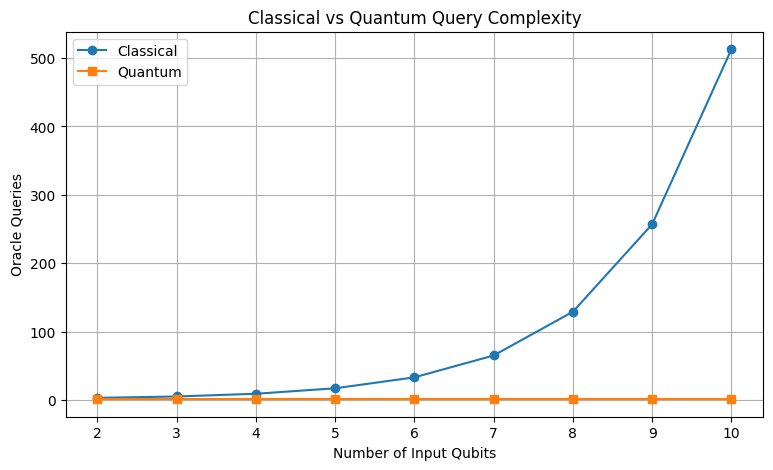

In [10]:
#Exercise 4 — Graph
n = np.arange(2, 11)

classical = 2**(n - 1) + 1
quantum = np.ones(len(n))

plt.figure(figsize=(9, 5))

plt.plot(n, classical, 'o-', label="Classical")
plt.plot(n, quantum, 's-', label="Quantum")

plt.xlabel("Number of Input Qubits")
plt.ylabel("Oracle Queries")
plt.title("Classical vs Quantum Query Complexity")

plt.grid()
plt.legend()
plt.show()

In [11]:
#Exercise 5 — Random Balanced Oracle
for n in range(2, 6):

    print(f"\nn = {n}")

    for test in range(5):

        qc = deutsch_jozsa(n, "random")

        result = sim.run(
            qc,
            shots=1024
        ).result()

        counts = result.get_counts()

        zero = "0" * n

        if zero not in counts:
            print(f"Test {test + 1}: BALANCED → {counts}")
        else:
            print(f"Test {test + 1}: CONSTANT → {counts}")


n = 2
Test 1: BALANCED → {'10': 1024}
Test 2: BALANCED → {'11': 1024}
Test 3: BALANCED → {'01': 1024}
Test 4: BALANCED → {'11': 1024}
Test 5: BALANCED → {'01': 1024}

n = 3
Test 1: BALANCED → {'111': 256, '001': 267, '010': 249, '100': 252}
Test 2: BALANCED → {'111': 1024}
Test 3: BALANCED → {'011': 246, '001': 276, '101': 261, '111': 241}
Test 4: BALANCED → {'110': 282, '100': 237, '101': 230, '111': 275}
Test 5: BALANCED → {'100': 255, '011': 239, '110': 255, '001': 275}

n = 4
Test 1: BALANCED → {'1111': 243, '0110': 251, '1110': 251, '0111': 279}
Test 2: BALANCED → {'1110': 66, '0001': 265, '1001': 57, '1010': 71, '1101': 79, '1111': 62, '0110': 246, '1100': 60, '1000': 61, '1011': 57}
Test 3: BALANCED → {'1010': 61, '0001': 236, '1011': 92, '0010': 61, '0101': 68, '0011': 69, '0110': 258, '0100': 53, '1100': 63, '1101': 63}
Test 4: BALANCED → {'1101': 237, '0100': 61, '1100': 57, '0011': 257, '0010': 76, '1001': 60, '0001': 68, '1111': 69, '0111': 72, '1010': 67}
Test 5: BALANCED